# Lab: Hierarchical and DBSCAN Clustering on the Wine Dataset

**Name:** Shreyas More  
**Course:** Advanced Big Data and Data Mining (MSCS-634-M50) - Full Term  
**Lab Assignment:** Clustering Techniques – Hierarchical and DBSCAN


In [43]:
## Step 1: Data Preparation and Exploration

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, homogeneity_score, completeness_score
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100


In [45]:
wine = load_wine()
df = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = wine.target   # true cultivar labels (used ONLY for evaluation, never for fitting)

print("Shape:", df.shape)
df.head()

Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [46]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

In [47]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [48]:


print("Missing values:", df.isna().sum().sum())
print("\nTrue class counts (cultivars):")
print(pd.Series(y_true).value_counts().sort_index())

Missing values: 0

True class counts (cultivars):
0    59
1    71
2    48
Name: count, dtype: int64


The 13 features are measured on very different scales (e.g., `proline` is in the hundreds/thousands while `hue` is around 1). Distance-based algorithms would be dominated by the large-scale features, so we **standardize** every feature to mean 0 and standard deviation 1.

In [49]:
scaler = StandardScaler()
X = scaler.fit_transform(df)

print("Means (rounded):", np.round(X.mean(axis=0), 3))
print("Stds  (rounded):", np.round(X.std(axis=0), 3))

# 2-D PCA projection used ONLY for visualization (clustering is done on all 13 standardized features)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print(f"\nVariance explained by PC1 + PC2: {pca.explained_variance_ratio_.sum():.1%}")

Means (rounded): [-0. -0. -0. -0. -0.  0. -0.  0. -0.  0.  0.  0. -0.]
Stds  (rounded): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Variance explained by PC1 + PC2: 55.4%


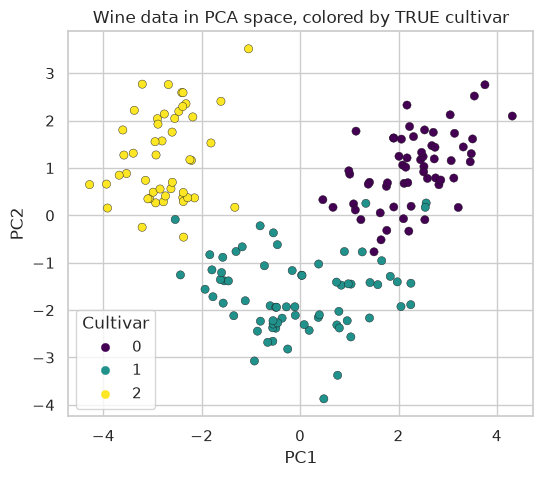

In [50]:
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap="viridis", s=35, edgecolor="k", linewidth=0.3)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title("Wine data in PCA space, colored by TRUE cultivar")
ax.legend(*sc.legend_elements(), title="Cultivar")
plt.show()

## Step 2: Hierarchical (Agglomerative) Clustering

We use Ward linkage (minimizes within-cluster variance) and try `n_clusters` = 2, 3, 4, 5.

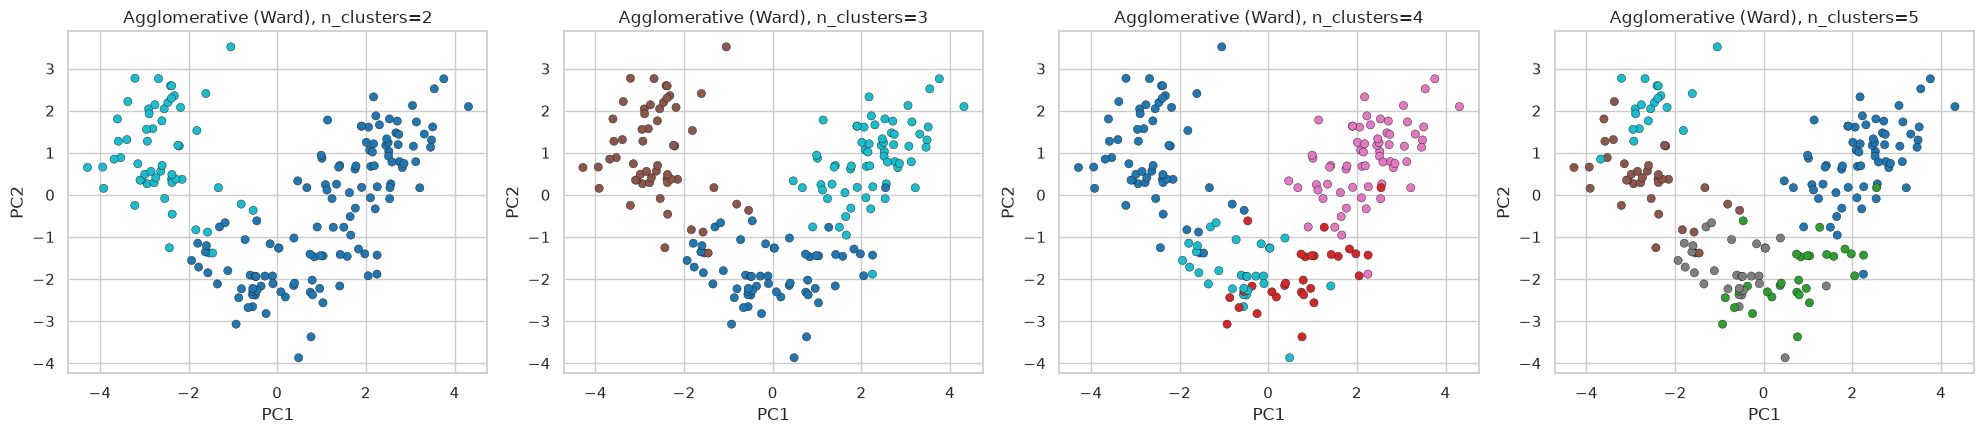

,n_clusters,Silhouette,Homogeneity,Completeness
0,2,0.267,0.444,0.774
1,3,0.277,0.790,0.783
2,4,0.226,0.790,0.649
3,5,0.187,0.811,0.576


In [51]:
ks = [2, 3, 4, 5]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
rows = []
for ax, k in zip(axes, ks):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap="tab10", s=35, edgecolor="k", linewidth=0.3)
    ax.set_title(f"Agglomerative (Ward), n_clusters={k}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    rows.append({"n_clusters": k,
                 "Silhouette": silhouette_score(X, labels),
                 "Homogeneity": homogeneity_score(y_true, labels),
                 "Completeness": completeness_score(y_true, labels)})
plt.tight_layout(); plt.show()
agg_results = pd.DataFrame(rows).round(3)
agg_results

### Effect of linkage method (n_clusters = 3)

In [52]:
rows = []
for link in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    rows.append({"linkage": link,
                 "cluster sizes": np.bincount(labels).tolist(),
                 "Silhouette": silhouette_score(X, labels),
                 "Homogeneity": homogeneity_score(y_true, labels),
                 "Completeness": completeness_score(y_true, labels)})
pd.DataFrame(rows).round(3)

,linkage,cluster sizes,Silhouette,Homogeneity,Completeness
0,ward,"[58, 56, 64]",0.277,0.790,0.783
1,complete,"[69, 58, 51]",0.204,0.616,0.613
2,average,"[174, 1, 3]",0.158,0.010,0.093
3,single,"[174, 3, 1]",0.183,0.019,0.175


### Dendrogram

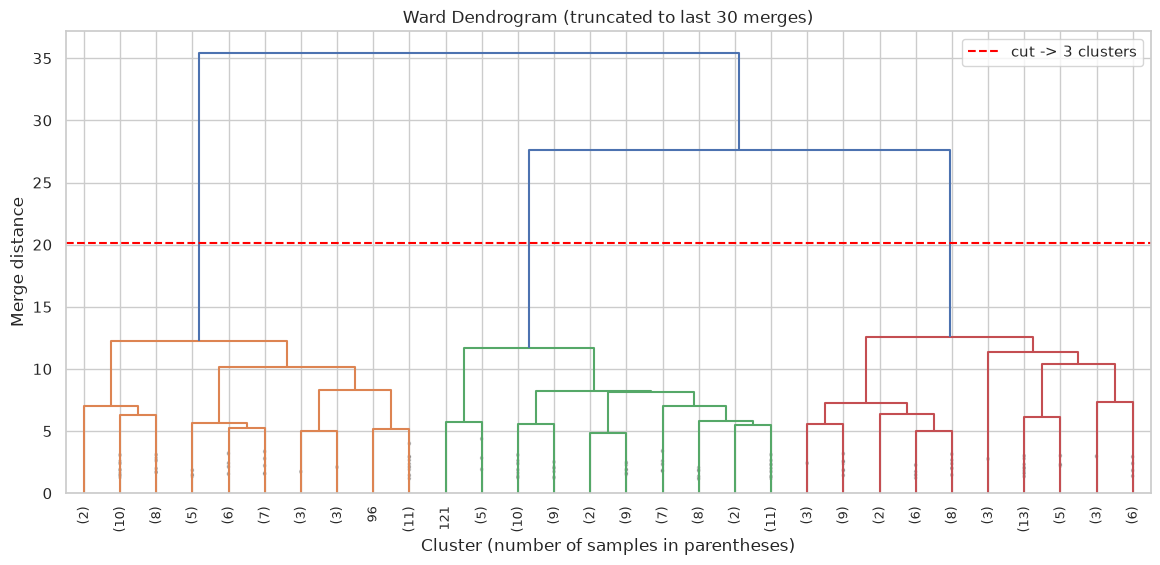

Last 6 merge distances: [11.38 11.72 12.23 12.57 27.65 35.4 ]


In [53]:
Z = linkage(X, method="ward")

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, ax=ax)
cut_height = (Z[-3, 2] + Z[-2, 2]) / 2   # a cut that leaves 3 clusters
ax.axhline(cut_height, color="red", linestyle="--", label="cut -> 3 clusters")
ax.set_title("Ward Dendrogram (truncated to last 30 merges)")
ax.set_xlabel("Cluster (number of samples in parentheses)")
ax.set_ylabel("Merge distance")
ax.legend()
plt.show()

print("Last 6 merge distances:", np.round(Z[-6:, 2], 2))

**Interpreting the dendrogram.** The height of each merge is the dissimilarity at which two clusters were joined. Look for the largest vertical gaps: cutting in a long gap gives clusters that are well separated. The red dashed line marks a cut that yields three clusters.

## Step 3: DBSCAN Clustering

### Choosing `eps` with a k-distance plot
For `min_samples = m`, we plot each point's distance to its m-th nearest neighbor, sorted. The "elbow" suggests a reasonable `eps`.

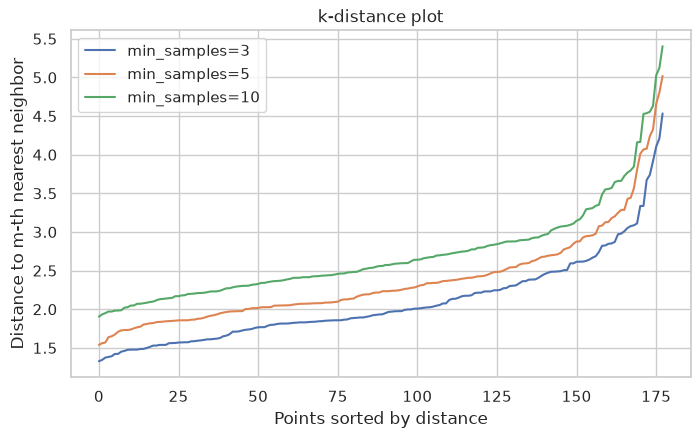

In [54]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in [3, 5, 10]:
    nn = NearestNeighbors(n_neighbors=m).fit(X)
    d, _ = nn.kneighbors(X)
    ax.plot(np.sort(d[:, -1]), label=f"min_samples={m}")
ax.set_xlabel("Points sorted by distance"); ax.set_ylabel("Distance to m-th nearest neighbor")
ax.set_title("k-distance plot"); ax.legend()
plt.show()

### Parameter experiment
We evaluate a grid of `eps` and `min_samples`. Silhouette is computed only on non-noise points (it needs at least 2 clusters). Homogeneity and completeness treat noise (`-1`) as its own label, so noise lowers those scores honestly.

In [55]:
def eval_dbscan(X, eps, m):
    labels = DBSCAN(eps=eps, min_samples=m).fit_predict(X)
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    sil = silhouette_score(X[mask], labels[mask]) if n_clusters >= 2 else np.nan
    return labels, {"eps": eps, "min_samples": m, "n_clusters": n_clusters,
                    "n_noise": int((~mask).sum()),
                    "Silhouette (non-noise)": sil,
                    "Homogeneity": homogeneity_score(y_true, labels),
                    "Completeness": completeness_score(y_true, labels)}

eps_grid = [1.5, 2.0, 2.2, 2.5, 3.0, 3.5]
ms_grid = [3, 5, 10]

results, all_labels = [], {}
for eps in eps_grid:
    for m in ms_grid:
        labels, r = eval_dbscan(X, eps, m)
        results.append(r); all_labels[(eps, m)] = labels
db_results = pd.DataFrame(results).round(3)
db_results

,eps,min_samples,n_clusters,n_noise,Silhouette (non-noise),Homogeneity,Completeness
0,1.5,3,8,147,0.331,0.189,0.251
1,1.5,5,0,178,NaN,0.000,1.000
2,1.5,10,0,178,NaN,0.000,1.000
3,2.0,3,5,64,0.211,0.442,0.372
4,2.0,5,5,85,0.240,0.362,0.325
5,2.0,10,1,139,NaN,0.289,0.596
6,2.2,3,3,44,0.073,0.486,0.481
7,2.2,5,2,55,0.348,0.410,0.428
8,2.2,10,2,89,0.394,0.331,0.384
9,2.5,3,1,23,NaN,0.067,0.189


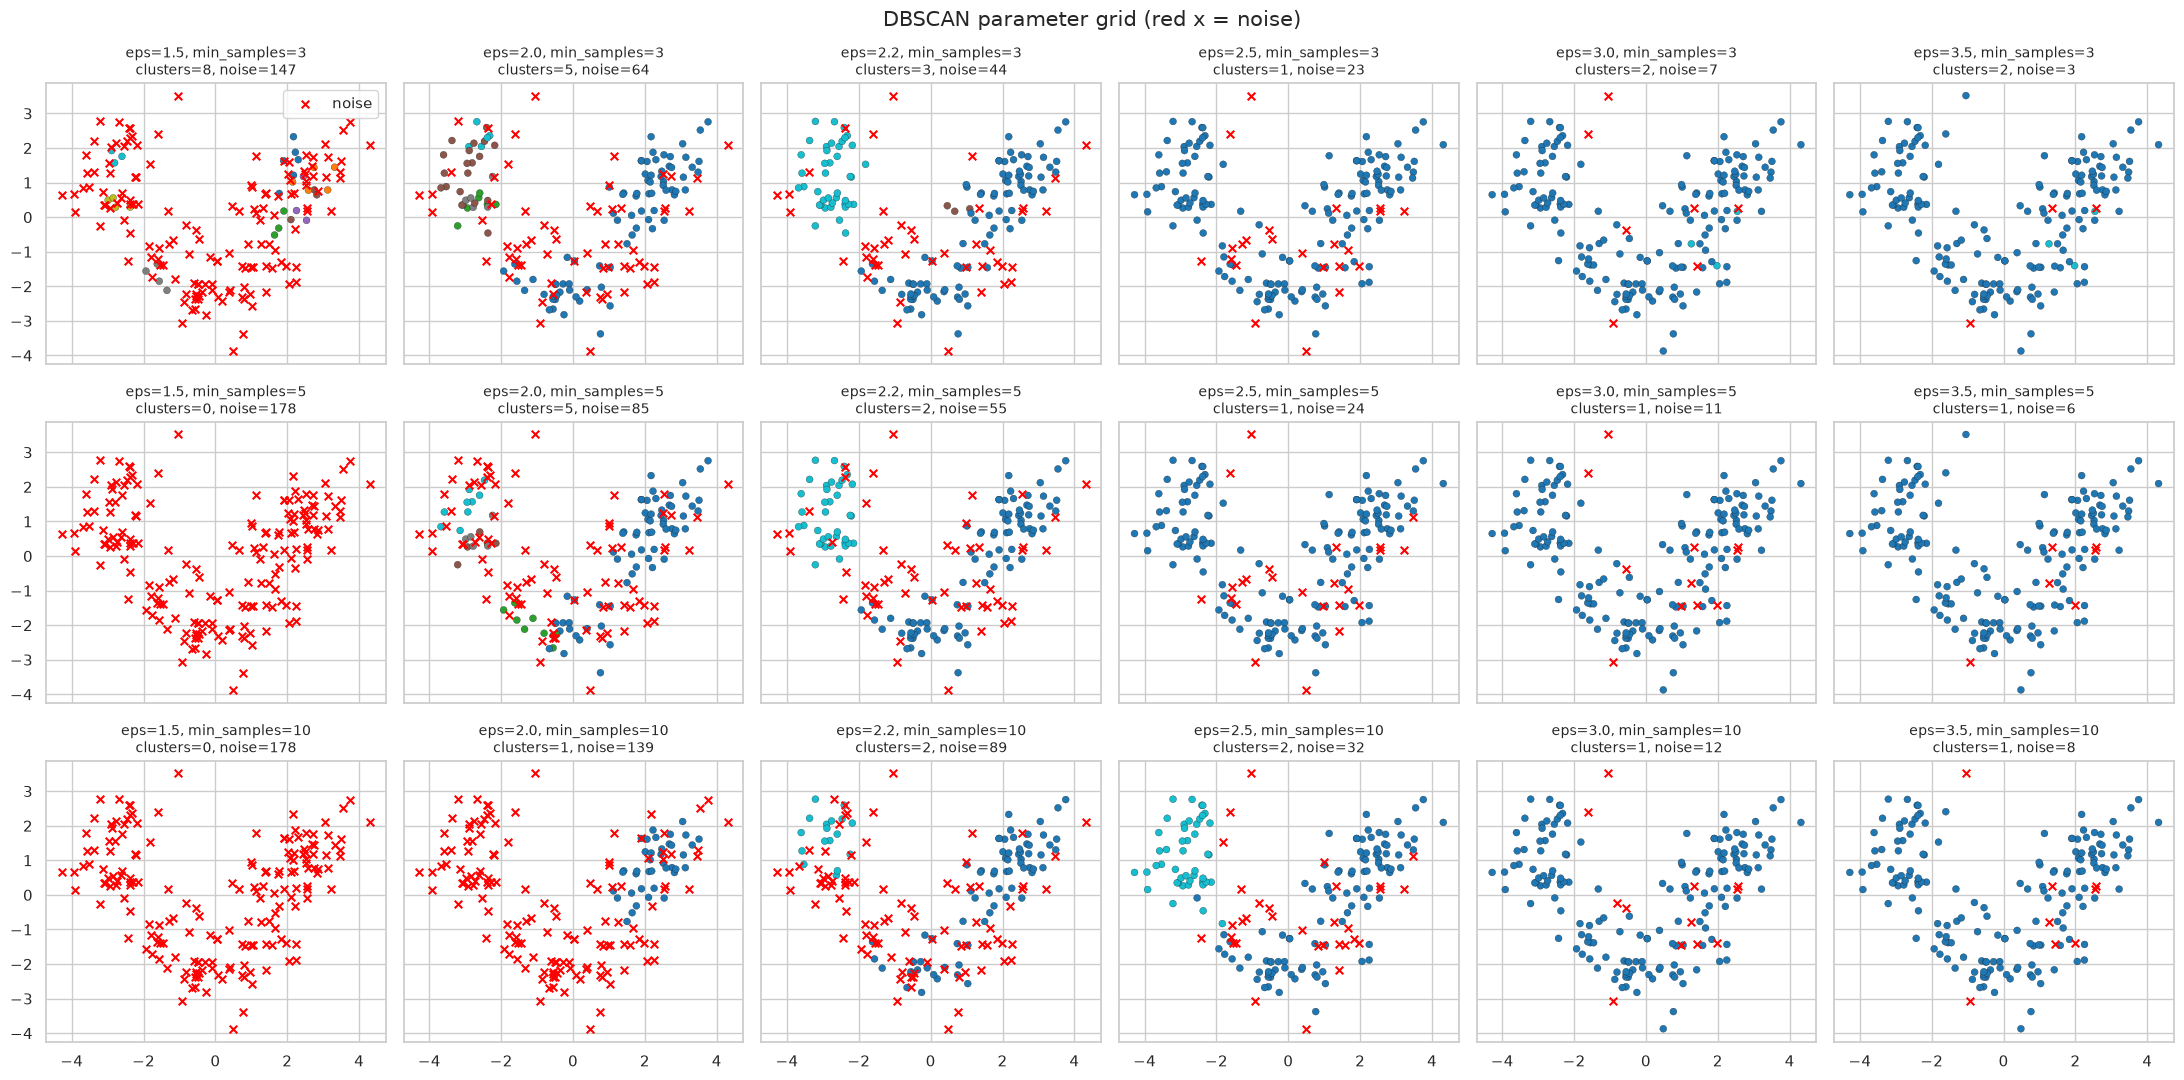

In [56]:
fig, axes = plt.subplots(len(ms_grid), len(eps_grid), figsize=(22, 11), sharex=True, sharey=True)
for i, m in enumerate(ms_grid):
    for j, eps in enumerate(eps_grid):
        ax = axes[i, j]
        labels = all_labels[(eps, m)]
        noise = labels == -1
        ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise], cmap="tab10", s=25, edgecolor="k", linewidth=0.2)
        ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="red", marker="x", s=30, label="noise")
        ax.set_title(f"eps={eps}, min_samples={m}\nclusters={len(set(labels[~noise]))}, noise={noise.sum()}", fontsize=10)
axes[0, 0].legend(loc="upper right")
fig.suptitle("DBSCAN parameter grid (red x = noise)", fontsize=15)
plt.tight_layout(); plt.show()

### Selecting the best DBSCAN configuration
We choose the setting with the highest mean of homogeneity and completeness among runs that find at least 2 clusters.

In [59]:
cand = db_results[db_results["n_clusters"] >= 2].copy()
cand["mean_HC"] = (cand["Homogeneity"] + cand["Completeness"]) / 2
best = cand.sort_values("mean_HC", ascending=False).iloc[0]
print(best)
best_eps, best_m = float(best["eps"]), int(best["min_samples"])
best_labels = all_labels[(best_eps, best_m)]

eps                        2.500
min_samples               10.000
n_clusters                 2.000
n_noise                   32.000
Silhouette (non-noise)     0.323
Homogeneity                0.504
Completeness               0.560
mean_HC                    0.532
Name: 11, dtype: float64


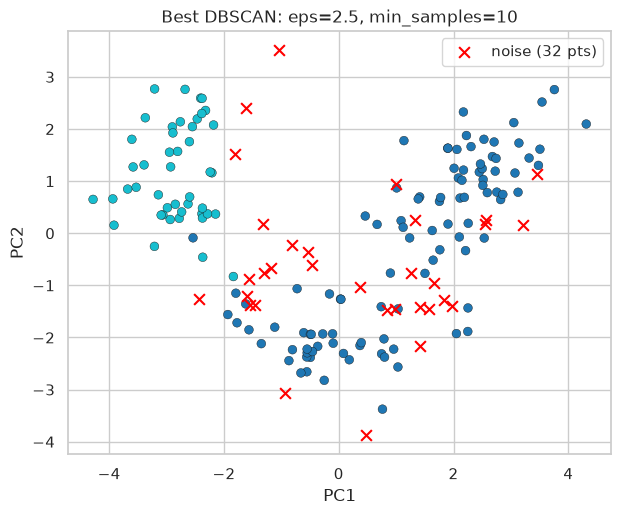

Cluster sizes (-1 = noise): {-1: 32, 0: 101, 1: 45}


In [60]:
noise = best_labels == -1
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=best_labels[~noise], cmap="tab10", s=40, edgecolor="k", linewidth=0.3)
ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c="red", marker="x", s=60, label=f"noise ({noise.sum()} pts)")
ax.set_title(f"Best DBSCAN: eps={best_eps}, min_samples={best_m}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
plt.show()

print("Cluster sizes (-1 = noise):", {int(k): int(v) for k, v in zip(*np.unique(best_labels, return_counts=True))})

In [ ]:
## Step 4: Analysis and Insights

### Side-by-side comparison of final models

In [61]:
agg3 = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
mask = best_labels != -1

comparison = pd.DataFrame({
    "Hierarchical (Ward, k=3)": {
        "Clusters": 3, "Noise points": 0,
        "Silhouette": silhouette_score(X, agg3),
        "Homogeneity": homogeneity_score(y_true, agg3),
        "Completeness": completeness_score(y_true, agg3)},
    f"DBSCAN (eps={best_eps}, min_samples={best_m})": {
        "Clusters": len(set(best_labels[mask])), "Noise points": int((~mask).sum()),
        "Silhouette": silhouette_score(X[mask], best_labels[mask]) if len(set(best_labels[mask])) >= 2 else np.nan,
        "Homogeneity": homogeneity_score(y_true, best_labels),
        "Completeness": completeness_score(y_true, best_labels)},
}).round(3)
comparison

,"Hierarchical (Ward, k=3)","DBSCAN (eps=2.5, min_samples=10)"
Clusters,3.000,2.000
Noise points,0.000,32.000
Silhouette,0.277,0.323
Homogeneity,0.790,0.504
Completeness,0.783,0.560


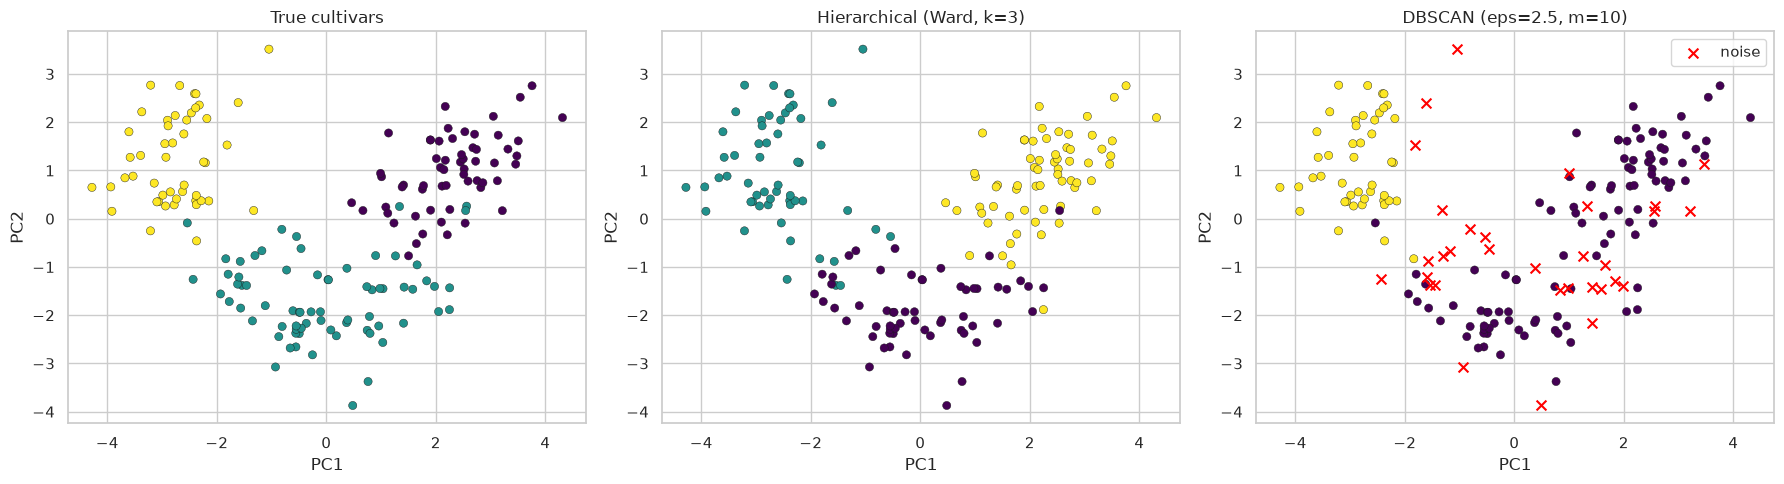

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
titles = ["True cultivars", "Hierarchical (Ward, k=3)", f"DBSCAN (eps={best_eps}, m={best_m})"]
for ax, lab, t in zip(axes, [y_true, agg3, best_labels], titles):
    nz = lab == -1
    ax.scatter(X_pca[~nz, 0], X_pca[~nz, 1], c=lab[~nz], cmap="viridis", s=35, edgecolor="k", linewidth=0.3)
    if nz.any():
        ax.scatter(X_pca[nz, 0], X_pca[nz, 1], c="red", marker="x", s=50, label="noise"); ax.legend()
    ax.set_title(t); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

### 4.1 Hierarchical vs. DBSCAN

| | Hierarchical (Ward, k=3) | DBSCAN (eps=2.5, min_samples=10) |
|---|---|---|
| Clusters found | 3 | 2 (+ 32 noise points) |
| Silhouette | 0.277 | 0.323 (non-noise points only) |
| Homogeneity | 0.790 | 0.504 |
| Completeness | 0.783 | 0.560 |

* **Hierarchical clustering recovered the true structure much better.** With Ward linkage and k = 3 it produced clusters of sizes 58 / 56 / 64, close to the true cultivar sizes (59 / 71 / 48), and its homogeneity and completeness are both about 0.79.
* **DBSCAN's higher silhouette is misleading.** It is computed only on the 146 non-noise points, after the hardest-to-assign points were removed, so it cannot be compared fairly with the hierarchical score computed on all 178 points. On the external metrics, which count noise as its own label, DBSCAN is clearly weaker (0.50 / 0.56).
* **The dendrogram supports k = 3.** The final merge distances were roughly 12.6 (4→3 clusters), 27.7 (3→2) and 35.4 (2→1). The large jump after the 4→3 merge means the three clusters are well separated, and this agrees with the three true cultivars. The silhouette score for the hierarchical model also peaks at k = 3 (0.277, vs. 0.267 for k = 2).

### 4.2 Influence of parameters

**Hierarchical**
* `n_clusters`: k = 2 merges cultivars (homogeneity only 0.44). k = 4 and k = 5 split real groups, so homogeneity stays high or rises slightly (0.79 → 0.81) while completeness falls (0.78 → 0.65 → 0.58). k = 3 gives the best balance.
* `linkage`: this mattered a lot. Ward gave balanced clusters. Complete linkage was weaker (silhouette 0.20, homogeneity 0.62). Average and single linkage produced one giant cluster of 174 points plus two or three outliers (homogeneity near 0.01–0.02), the "chaining" effect.

**DBSCAN**
* `eps` and `min_samples` acted together, and the results were very sensitive:
  * **Small eps (1.5)**: with min_samples = 3 it fragments the data into 8 small clusters with 147 noise points. With min_samples ≥ 5 *every* point is noise.
  * **Large eps (3.0–3.5)**: almost all points merge into one or two clusters with only a few noise points, so the clusters carry little information (homogeneity ≈ 0.03).
  * **Intermediate eps (2.2–2.5)**: the only range where DBSCAN found a meaningful split. Increasing `min_samples` at fixed eps made the algorithm stricter, so noise grew (e.g. 24 → 32 noise points at eps = 2.5 when going from 5 to 10) and weakly connected points were dropped.
* The best setting found in our grid (eps = 2.5, min_samples = 10) still only found two clusters, so none of the tested settings reproduced all three cultivars.

### 4.3 Strengths and weaknesses

| | Strengths | Weaknesses (seen in this lab) |
|---|---|---|
| **Hierarchical** | No need for density assumptions; the dendrogram shows the structure at every level and helps choose k; Ward works well on compact, similarly sized groups like these; deterministic. | Must choose k (or a cut height); forces every point into a cluster, including outliers; very dependent on the linkage (single/average failed here); O(n²) memory/time, so it does not scale well to large data. |
| **DBSCAN** | Does not need k; can find arbitrarily shaped clusters; explicitly flags outliers as noise. | Extremely sensitive to `eps` and `min_samples`; a single global density does not suit clusters of different densities; in 13 dimensions distances become less discriminating (curse of dimensionality), and the Wine cultivars overlap, so it struggles; noise points hurt external metrics. |

### 4.4 Conclusion

For the standardized Wine data, whose true groups are roughly spherical, similar in size and overlapping, **Ward hierarchical clustering with k = 3 is the better choice**. DBSCAN is better suited to data with irregular cluster shapes, clearly density-separated clusters, or many outliers, none of which describe this dataset well. A useful next step would be to run DBSCAN on the PCA-reduced data or on a selected subset of features, which might make density estimates more reliable.

*Note: the true cultivar labels were used only to compute homogeneity and completeness, never to fit any model.*
